# Tome 15, Appendix I: The abc Conjecture (Python companion)

Exercises first, solutions at the end. We list all abc hits with $c\le10^6$, look at the families of Proposition 8.1 and Exercise
8.2, test Mason--Stothers (Theorem 8.2) with `sympy`, search for solutions of the Fermat--Catalan equation, and check the
Erd\H os--Straus identities of Theorem 8.9 and the conjecture itself for all $n\le10^5$. We use `numpy`, `sympy` and `matplotlib`.

*Before each solution, predict what the output will look like.*

In [1]:
import math, itertools, time
from fractions import Fraction as Fr
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

## Exercises

**P9.1 (★★) All abc hits up to $10^6$.** Sieve the radicals, and for each $c$ look only at the $a$ with $\operatorname{rad}(a)<c/\operatorname{rad}(c)$,
grouped by radical. List the ten best triples and draw the histogram of qualities.

**P9.2 (★) Hits on demand.** For $k\le6$ compute $c/\operatorname{rad}(abc)$ for $(1,3^{2^k}-1,3^{2^k})$, and for the primes $p\le11$ the same ratio for
$(1,2^{p(p-1)}-1,2^{p(p-1)})$ (factorisations by `sympy`; larger cases are beyond quick factoring). Check $p^2\mid2^{p(p-1)}-1$ for all $p<1000$.

**P9.3 (★) Mason--Stothers.** For random coprime polynomials $a$, $b$ with small integer coefficients, compute $\max\deg$ and $n_0(abc)-1$ for
$c=a+b$, and check the theorem. Then check the cases of equality of Exercises 8.3 and 8.5.

**P9.4 (★★) Fermat--Catalan.** Check the ten known solutions. Then find all $u+v=w$ with $u,v,w$ perfect powers up to $10^8$, coprime, whose exponents
can be chosen with $\frac1p+\frac1q+\frac1r<1$.

**P9.5 (★★) Erd\H os--Straus.** Verify the identities of Theorem 8.9 on many $n$, list the primes below $10^5$ in the six classes, and find a
solution of $\frac4p=\frac1x+\frac1y+\frac1z$ for each of them. Why does this prove the conjecture for every $n\le10^5$?

## Solutions

### P9.1
For each $c$ with $L=c/\operatorname{rad}(c)\ge2$, a hit needs $\operatorname{rad}(a)\operatorname{rad}(b)<L$; most $c$ have a radical close to $c$, so the
search is short. (About a minute in pure Python.)

1269 hits with c <= 10^6 (60 s)
1.56789   1 + 4374 = 4375   = {} + {2: 1, 3: 7} = {5: 4, 7: 1}
1.54708   343 + 59049 = 59392   = {7: 3} + {3: 10} = {2: 11, 29: 1}
1.48887   121 + 255879 = 256000   = {11: 2} + {3: 9, 13: 1} = {2: 11, 5: 3}
1.48291   37 + 32768 = 32805   = {37: 1} + {2: 15} = {3: 8, 5: 1}
1.45567   1 + 2400 = 2401   = {} + {2: 5, 3: 1, 5: 2} = {7: 4}
1.44506   338 + 390625 = 390963   = {2: 1, 13: 2} + {5: 8} = {3: 1, 19: 4}
1.44331   1 + 512000 = 512001   = {} + {2: 12, 5: 3} = {3: 5, 7: 2, 43: 1}
1.43501   7168 + 78125 = 85293   = {2: 10, 7: 1} + {5: 7} = {3: 8, 13: 1}
1.42657   3 + 125 = 128   = {3: 1} + {5: 3} = {2: 7}
1.41268   5 + 177147 = 177152   = {5: 1} + {3: 11} = {2: 10, 173: 1}


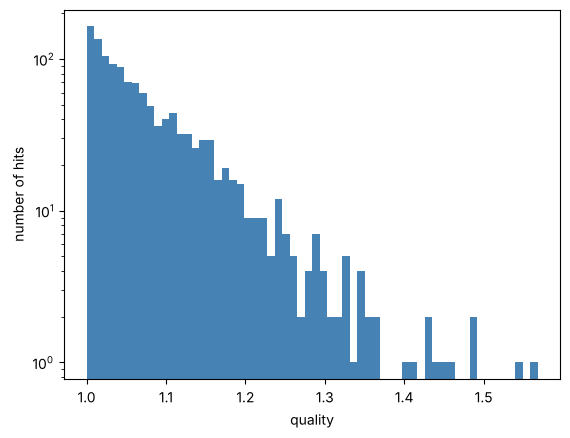

In [2]:
t0 = time.time()
N = 10**6
rad = np.ones(N + 1, dtype=np.int64)
for p in range(2, N + 1):
    if rad[p] == 1:
        rad[p::p] *= p
order = np.argsort(rad[1:], kind='stable') + 1
starts = np.searchsorted(rad[order], np.arange(N + 2)).tolist()
radl, orderl = rad.tolist(), order.tolist()
hits = []
for c in range(3, N + 1):
    rc = radl[c]; L = c // rc
    if L < 2: continue
    for r in range(1, L):
        for k in range(starts[r], starts[r + 1]):
            a = orderl[k]
            if 2 * a >= c: break
            b = c - a
            if r * radl[b] * rc < c and math.gcd(a, c) == 1:
                hits.append((math.log(c) / math.log(r * radl[b] * rc), a, b, c))
hits.sort(reverse=True)
print(len(hits), 'hits with c <= 10^6 (%.0f s)' % (time.time() - t0))
for q, a, b, c in hits[:10]:
    print('%.5f   %d + %d = %d   = %s + %s = %s' % (q, a, b, c, sp.factorint(a), sp.factorint(b), sp.factorint(c)))
plt.hist([h[0] for h in hits], bins=60, color='steelblue')
plt.xlabel('quality'); plt.ylabel('number of hits'); plt.yscale('log'); plt.show()

$1269$ hits below $10^6$ (and $3504$ below $10^7$, by the compiled version used for Figure 8.1). The best is $1+2\cdot3^7=5^4\cdot7$, of
quality $1.5679$; Reyssat's $2+3^{10}\cdot109=23^5$ is just above $6\cdot10^6$. The histogram falls off fast: qualities above $1.4$ are a handful.

### P9.2

In [3]:
def radical(n): return math.prod(sp.factorint(n))
for k in range(1, 7):
    c = 3**(2**k); b = c - 1
    print('k = %2d: c/rad = %.2f   (bound 2^(k+1)/3 = %.2f)' % (k, c / (3 * radical(b)), 2**(k + 1) / 3))
for p in sp.primerange(3, 12):
    c = 2**(p * (p - 1)); b = c - 1
    print('p = %2d: c/rad = %.3g   (bound p/2 = %.1f)' % (p, c / (2 * radical(b)), p / 2))
print('p^2 divides 2^(p(p-1)) - 1 for all odd p < 1000:', all(pow(2, p * (p - 1), p * p) == 1 for p in sp.primerange(3, 1000)))

k =  1: c/rad = 1.50   (bound 2^(k+1)/3 = 1.33)
k =  2: c/rad = 2.70   (bound 2^(k+1)/3 = 2.67)
k =  3: c/rad = 5.33   (bound 2^(k+1)/3 = 5.33)
k =  4: c/rad = 10.67   (bound 2^(k+1)/3 = 10.67)
k =  5: c/rad = 21.33   (bound 2^(k+1)/3 = 21.33)
k =  6: c/rad = 42.67   (bound 2^(k+1)/3 = 42.67)
p =  3: c/rad = 1.52   (bound p/2 = 1.5)
p =  5: c/rad = 2.5   (bound p/2 = 2.5)
p =  7: c/rad = 10.5   (bound p/2 = 3.5)
p = 11: c/rad = 5.5   (bound p/2 = 5.5)
p^2 divides 2^(p(p-1)) - 1 for all odd p < 1000: True


Both families stay just above their bounds, sometimes by a hair: apart from the forced factors $2^{k+2}$ and $p^2$, the numbers $3^{2^k}-1$ and
$2^{p(p-1)}-1$ are nearly squarefree here (with exceptions, such as $p=7$, where $2^{42}-1$ has the extra square factor $3^2$). The ratios grow, but
slowly compared with $c$: the qualities $\log c/\log\operatorname{rad}$ tend to $1$, consistent with abc.

### P9.3

In [4]:
t = sp.symbols('t')
rng = np.random.default_rng(9)
def n0(f): return sp.degree(sp.Poly(sp.sqf_part(f), t))
worst = None
for _ in range(200):
    while True:
        a = sp.Poly(rng.integers(-3, 4, size=int(rng.integers(2, 6))).tolist(), t).as_expr()
        b = sp.Poly(rng.integers(-3, 4, size=int(rng.integers(2, 6))).tolist(), t).as_expr()
        if sp.gcd(a, b) == 1 and sp.expand(a + b) != 0 and not (sp.degree(a, t) <= 0 and sp.degree(b, t) <= 0): break
    c = sp.expand(a + b)
    gap = n0(sp.expand(a * b * c)) - 1 - max(sp.degree(a, t), sp.degree(b, t), sp.degree(c, t))
    assert gap >= 0
    worst = gap if worst is None else min(worst, gap)
print('random triples: smallest slack n0(abc) - 1 - max deg =', worst)
for n in range(1, 8):
    a, b = t**n, 1; c = a + b
    print('t^%d + 1: max deg = %d, n0 - 1 = %d' % (n, n, n0(sp.expand(a * b * c)) - 1))
x, y, z = t**2 - 1, 2 * t, t**2 + 1
print('Pythagorean:', sp.expand(x**2 + y**2 - z**2) == 0, 'max deg', 4, 'n0 - 1 =', n0(sp.expand(x**2 * y**2 * z**2)) - 1)

random triples: smallest slack n0(abc) - 1 - max deg = 0
t^1 + 1: max deg = 1, n0 - 1 = 1
t^2 + 1: max deg = 2, n0 - 1 = 2
t^3 + 1: max deg = 3, n0 - 1 = 3
t^4 + 1: max deg = 4, n0 - 1 = 4
t^5 + 1: max deg = 5, n0 - 1 = 5
t^6 + 1: max deg = 6, n0 - 1 = 6
t^7 + 1: max deg = 7, n0 - 1 = 7
Pythagorean: True max deg 4 n0 - 1 = 4


The theorem holds in every random case, sometimes with equality, and equality holds for $t^n+1$ and for the Pythagorean triple.

### P9.4
We keep, for each perfect power, its largest exponent (the smallest $\frac1p$), and use a set for the lookups.

In [5]:
known = [(1, 7, 2, 3, 3, 2), (2, 5, 7, 2, 3, 4), (7, 3, 13, 2, 2, 9), (2, 7, 17, 3, 71, 2), (3, 5, 11, 4, 122, 2), (17, 7, 76271, 3, 21063928, 2),
         (1414, 3, 2213459, 2, 65, 7), (9262, 3, 15312283, 2, 113, 7), (43, 8, 96222, 3, 30042907, 2), (33, 8, 1549034, 2, 15613, 3)]
for x, p, y, q, z, r in known:
    assert x**p + y**q == z**r and math.gcd(x, y) == 1 and Fr(1, p) + Fr(1, q) + Fr(1, r) < 1
print('the ten known solutions check out')
B = 10**8
best = {}
for e in range(2, 27):
    for base in range(2, int(round(B ** (1 / e))) + 2):
        v = base**e
        if v <= B: best[v] = max(best.get(v, 0), e)
best[1] = 10**9          # 1 = 1^m for every m
P = sorted(best)
found = []
for w in P:
    if w < 2: continue
    for u in P:
        if 2 * u > w: break
        v = w - u
        if v in best and math.gcd(u, v) == 1 and Fr(1, best[u]) + Fr(1, best[v]) + Fr(1, best[w]) < 1:
            found.append((u, v, w))
print(len(P), 'perfect powers up to 10^8;', 'solutions:', found)

the ten known solutions check out


10491 perfect powers up to 10^8; solutions: [(1, 8, 9), (32, 49, 81), (169, 343, 512), (128, 4913, 5041), (243, 14641, 14884)]


Below $10^8$ the search finds exactly the five small known solutions, $1+8=9$, $32+49=81$, $128+4913=5041$, $243+14641=14884$ and $169+343=512$ (with
the terms in increasing order). The other five known solutions are far beyond: their largest terms have $15$ to $30$ digits.

### P9.5
For a prime $p$, try $x=\lceil p/4\rceil,\lceil p/4\rceil+1,\dots$ and write $\frac4p-\frac1x=\frac uv$ in lowest terms. Then $\frac uv=\frac1y+\frac1z$
exactly when $(uy-v)(uz-v)=v^2$, so we run over the divisors $d\le v$ of $v^2$ with $d\equiv-v\pmod u$ and put $y=\frac{v+d}u$, $z=\frac{v+v^2/d}u$.

In [6]:
def lemma(a, b, c, d):
    n = (4*a*b*c*d - a - b) // c
    assert Fr(4, n) == Fr(1, a*b*d) + Fr(1, a*c*d*n) + Fr(1, b*c*d*n)
    return n
rows = [(1, 1, 2), (1, 2, 1), (1, 5, 2), (2, 5, 1), (1, 21, 2), (2, 21, 1), (1, 14, 1)]
for a, b, c in rows:
    print((a, b, c), [lemma(a, b, c, d) for d in range(1, 6)])
for k in range(1000):
    n = 3*k + 2; assert Fr(4, n) == Fr(1, n) + Fr(1, k + 1) + Fr(1, (k + 1) * n)
classes = [1, 121, 169, 289, 361, 529]
hard = [p for p in sp.primerange(2, 10**5) if p % 840 in classes]
print(len(hard), 'primes below 10^5 in the six classes; the first:', hard[:8])

def es_prime(p):
    x = (p + 3) // 4
    while True:
        u, v = 4*x - p, p*x
        g = math.gcd(u, v); u //= g; v //= g
        f = sp.factorint(v)
        sq = {q: 2*e for q, e in f.items()}
        for d in sorted(sp.divisors(sp.Mul(*[q**e for q, e in sq.items()]))):
            if d > v: break
            if (v + d) % u == 0:
                y, z = (v + d) // u, (v + v*v // d) // u
                assert Fr(4, p) == Fr(1, x) + Fr(1, y) + Fr(1, z)
                return x, y, z
        x += 1
t0 = time.time()
sols = {p: es_prime(p) for p in hard}
steps = max(sols[p][0] - (p + 3)//4 for p in hard)
print('all %d solved in %.1f s; x never exceeds ceil(p/4) + %d' % (len(hard), time.time() - t0, steps))
print('p = 1009:', sols[1009])

(1, 1, 2) [3, 7, 11, 15, 19]
(1, 2, 1) [5, 13, 21, 29, 37]
(1, 5, 2) [17, 37, 57, 77, 97]
(2, 5, 1) [33, 73, 113, 153, 193]
(1, 21, 2) [73, 157, 241, 325, 409]
(2, 21, 1) [145, 313, 481, 649, 817]
(1, 14, 1) [41, 97, 153, 209, 265]
273 primes below 10^5 in the six classes; the first: [1009, 1129, 1201, 1801, 2521, 2689, 3049, 3361]


all 273 solved in 0.2 s; x never exceeds ceil(p/4) + 7
p = 1009: (253, 85096, 1974822872)


All the identities hold, there are $273$ primes below $10^5$ in the six classes, and each has a solution with $x$ at most $7$ steps above $\frac p4$ (for $p=1009$ the search
finds a different solution from the one of Exercise 8.9: there are many). This
proves the conjecture for every $n\le10^5$: if $n$ has a prime factor outside the six classes, Theorem 8.9 applies; otherwise $n$ has a prime
factor $p\le10^5$ in the six classes, solved here, and Proposition 8.7 passes the solution to $n$. The search is fast because $\frac4p$ has
many representations; what is missing is a proof that there is always one.